In [1]:
import os
import torch
import torchvision.transforms as transforms
from PIL import Image
import numpy as np

# 1. BÚSQUEDA RECURSIVA DE IMÁGENES
ruta_carpeta = "C:/ia/parcial 2/dataset quirpinchaca 03"
extensiones_validas = ('.jpg', '.jpeg', '.png', '.bmp')

rutas_imagenes = []
for root, _, files in os.walk(ruta_carpeta):
    for file in files:
        if file.lower().endswith(extensiones_validas):
            rutas_imagenes.append(os.path.join(root, file))

rutas_imagenes = sorted(rutas_imagenes)
print(f"Total de imágenes originales encontradas: {len(rutas_imagenes)}")

# 2. TRANSFORMACIÓN Y TROCEADO NÍTIDO (256x256 -> 4 recortes directos de 64x64)
transform_256 = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor()
])

vectores_trozos = []
rutas_trozos_origen = []

for idx, ruta in enumerate(rutas_imagenes):
    try:
        img = Image.open(ruta).convert('RGB')
        tensor_img = transform_256(img) # Tensor (3, 256, 256)
        
        # Recortes de 64x64 a escala real 1:1
        t1 = tensor_img[:, 32:96, 32:96]     # Cuadrante 1 (Sup. Izq)
        t2 = tensor_img[:, 32:96, 160:224]   # Cuadrante 2 (Sup. Der)
        t3 = tensor_img[:, 160:224, 32:96]   # Cuadrante 3 (Inf. Izq)
        t4 = tensor_img[:, 160:224, 160:224] # Cuadrante 4 (Inf. Der)
        
        for trozo in [t1, t2, t3, t4]:
            vectores_trozos.append(trozo.reshape(-1))
            rutas_trozos_origen.append(idx)
    except Exception as e:
        continue

# Matriz final de características extendida (892 muestras x 12288 características)
X_trozos = torch.stack(vectores_trozos).numpy()

print(f"Total de trozos nítidos generados: {X_trozos.shape[0]} muestras")
print(f"Forma de la matriz X_trozos: {X_trozos.shape}")

Total de imágenes originales encontradas: 223
Total de trozos nítidos generados: 892 muestras
Forma de la matriz X_trozos: (892, 12288)


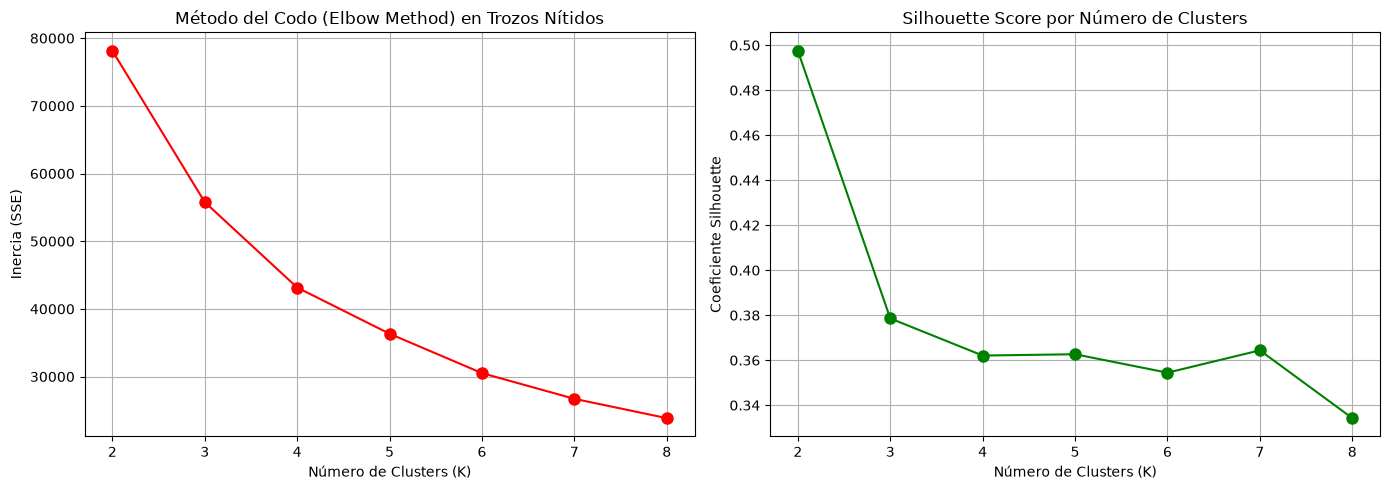

K = 2 -> Silhouette Score: 0.4976
K = 3 -> Silhouette Score: 0.3786
K = 4 -> Silhouette Score: 0.3621
K = 5 -> Silhouette Score: 0.3627
K = 6 -> Silhouette Score: 0.3545
K = 7 -> Silhouette Score: 0.3644
K = 8 -> Silhouette Score: 0.3343


In [2]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np

# 1. REDUCCIÓN DE DIMENSIONALIDAD CON PCA (Para acelerar y limpiar la búsqueda de clusters)
pca_trozos = PCA(n_components=2, random_state=42)
X_pca_trozos = pca_trozos.fit_transform(X_trozos)

# 2. CÁLCULO DE INERCIAS (SSE) Y SILHOUETTE SCORES PARA DIFERENTES VALORES DE K (2 a 8)
inercias = []
silhouette_scores = []
K_rango = range(2, 9)

for k in K_rango:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans_temp.fit_predict(X_pca_trozos)
    
    inercias.append(kmeans_temp.inertia_)
    score = silhouette_score(X_pca_trozos, labels)
    silhouette_scores.append(score)

# 3. GRAFICAR EL MÉTODO DEL CODO Y EL SILHOUETTE SCORE
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica 1: Método del Codo
ax[0].plot(K_rango, inercias, 'ro-', markersize=8)
ax[0].set_title("Método del Codo (Elbow Method) en Trozos Nítidos")
ax[0].set_xlabel("Número de Clusters (K)")
ax[0].set_ylabel("Inercia (SSE)")
ax[0].grid(True)

# Gráfica 2: Silhouette Score
ax[1].plot(K_rango, silhouette_scores, 'go-', markersize=8)
ax[1].set_title("Silhouette Score por Número de Clusters")
ax[1].set_xlabel("Número de Clusters (K)")
ax[1].set_ylabel("Coeficiente Silhouette")
ax[1].grid(True)

plt.tight_layout()
plt.show()

# Imprimir las métricas obtenidas
for k, s in zip(K_rango, silhouette_scores):
    print(f"K = {k} -> Silhouette Score: {s:.4f}")

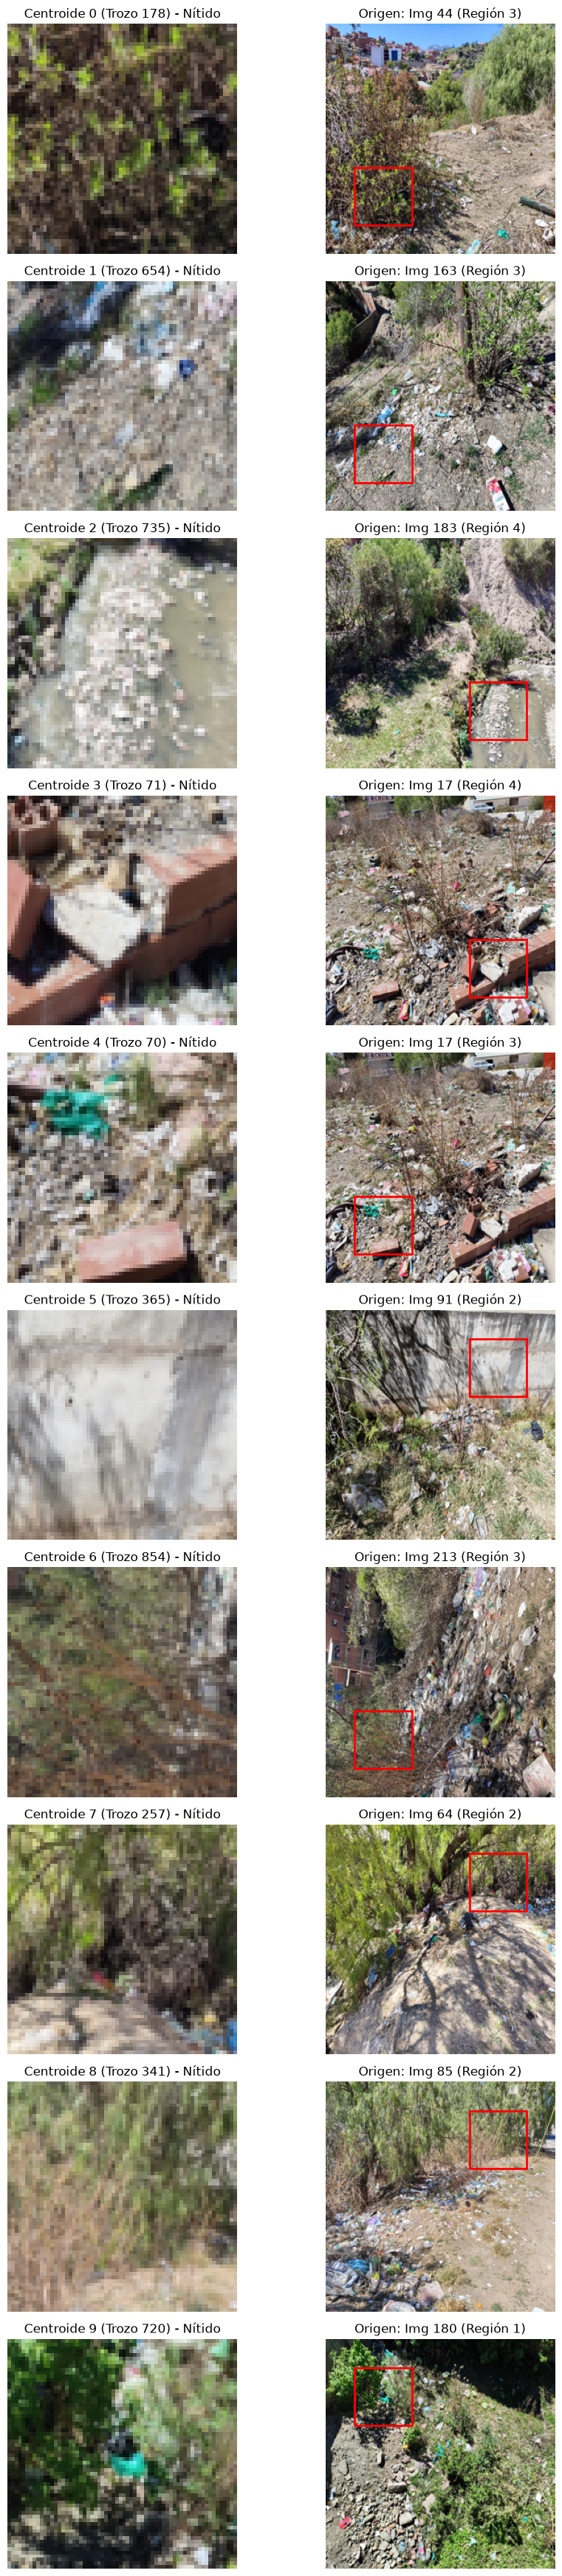

In [3]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# 1. REDUCCIÓN DE DIMENSIONALIDAD CON PCA
pca_trozos = PCA(n_components=2, random_state=42)
X_pca_trozos = pca_trozos.fit_transform(X_trozos)

# 2. AGRUPAMIENTO NO SUPERVISADO (K-Means con K=10 -> 10 centroides a etiquetar)
k_clases = 10
kmeans_trozos = KMeans(n_clusters=k_clases, random_state=42, n_init=10)
etiquetas_clusters_trozos = kmeans_trozos.fit_predict(X_pca_trozos)

# 3. EXTRAER LOS 4 TROZOS CENTROIDES
indices_centroides_trozos = []
for i in range(k_clases):
    centro = kmeans_trozos.cluster_centers_[i]
    distancias = np.linalg.norm(X_pca_trozos[etiquetas_clusters_trozos == i] - centro, axis=1)
    idx_relativo = np.argmin(distancias)
    idx_real = np.where(etiquetas_clusters_trozos == i)[0][idx_relativo]
    indices_centroides_trozos.append(idx_real)

# 4. DICCIONARIO DE CLASES DE VEGETACIÓN
diccionario_clases = {0: "Árbol", 1: "Arbusto", 2: "Maleza", 3: "Pasto"}

# 5. VISUALIZACIÓN NÍTIDA DE LOS 4 CENTROIDES Y SU IMAGEN ORIGEN
fig, axes = plt.subplots(k_clases, 2, figsize=(10, 3.5 * k_clases))

coords_cuadrantes = [
    (32, 32, 64, 64),    # Región 1
    (160, 32, 64, 64),   # Región 2
    (32, 160, 64, 64),   # Región 3
    (160, 160, 64, 64)   # Región 4
]

for i, idx_trozo in enumerate(indices_centroides_trozos):
    idx_img_origen = rutas_trozos_origen[idx_trozo]
    num_cuadrante = idx_trozo % 4
    
    img_trozo = X_trozos[idx_trozo].reshape(3, 64, 64).transpose(1, 2, 0)
    img_original = Image.open(rutas_imagenes[idx_img_origen]).convert('RGB').resize((256, 256))
    
    # Trozo recortado
    axes[i, 0].imshow(img_trozo)
    axes[i, 0].set_title(f"Centroide {i} (Trozo {idx_trozo}) - Nítido")
    axes[i, 0].axis('off')
    
    # Imagen completa con recuadro rojo
    axes[i, 1].imshow(img_original)
    x, y, w, h = coords_cuadrantes[num_cuadrante]
    rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor='r', facecolor='none')
    axes[i, 1].add_patch(rect)
    axes[i, 1].set_title(f"Origen: Img {idx_img_origen} (Región {num_cuadrante+1})")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

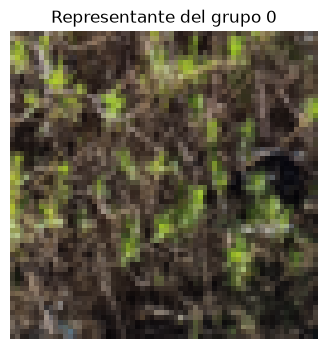

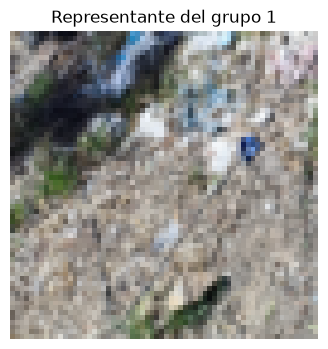

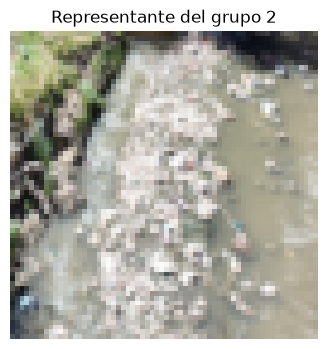

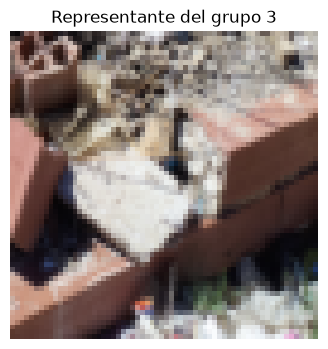

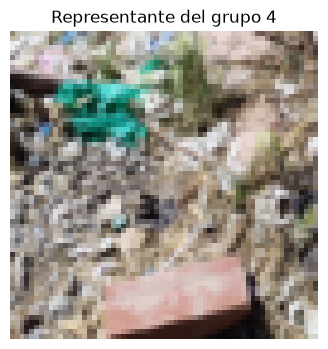

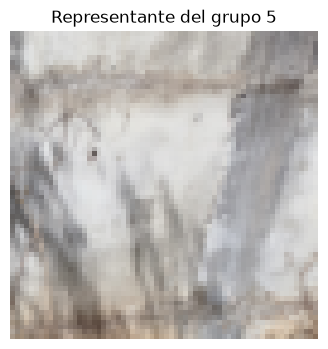

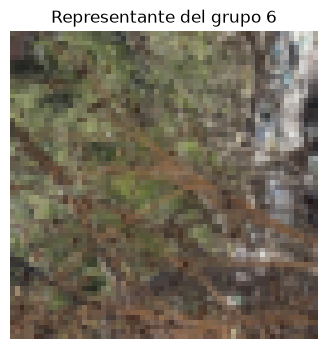

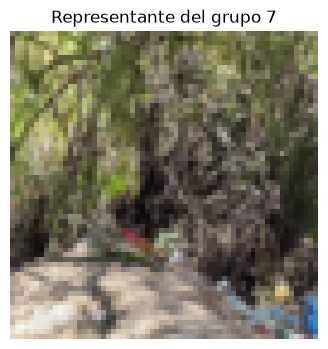

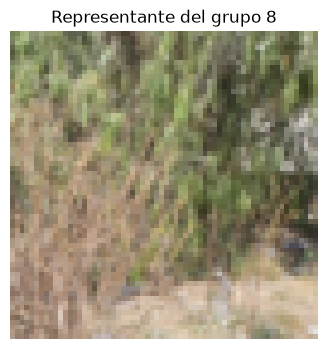

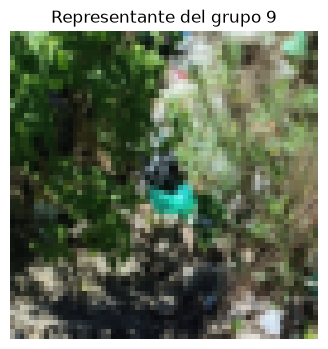


Etiquetas asignadas: [1 4 4 4 1 4 0 1 0 0]
Representantes etiquetados: 10
Grupo 0: maleza
Grupo 1: sin_vegetacion
Grupo 2: sin_vegetacion
Grupo 3: sin_vegetacion
Grupo 4: maleza
Grupo 5: sin_vegetacion
Grupo 6: arboles
Grupo 7: maleza
Grupo 8: arboles
Grupo 9: arboles


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Clases definidas para el etiquetado
CLASSES = ["arboles", "maleza", "arbusto", "pasto", "sin_vegetacion"]

menu = ", ".join(f"{i}={name}" for i, name in enumerate(CLASSES))
y_representative = []

for i, idx_trozo in enumerate(indices_centroides_trozos):
    # Mostrar el trozo centroide
    plt.figure(figsize=(4, 4))
    plt.imshow(X_trozos[idx_trozo].reshape(3, 64, 64).transpose(1, 2, 0))
    plt.title(f"Representante del grupo {i}")
    plt.axis("off")
    plt.show()

    label = int(input(f"Etiqueta ({menu}, -1=No identificable): "))

    while label not in [-1] + list(range(len(CLASSES))):
        label = int(input(f"Introduce solamente -1 o un número de 0 a {len(CLASSES) - 1}: "))

    y_representative.append(label)

y_representative = np.array(y_representative)

# Identificar los representantes que pudimos etiquetar
valid_labels = y_representative != -1

print("\nEtiquetas asignadas:", y_representative)
print("Representantes etiquetados:", np.sum(valid_labels))
for i, label in enumerate(y_representative):
    name = CLASSES[label] if label != -1 else "No identificable"
    print(f"Grupo {i}: {name}")


In [5]:
import numpy as np

rutas_idx = np.array(rutas_trozos_origen)   # foto de origen de cada trozo
indices_centroides_trozos = np.array(indices_centroides_trozos)
rng = np.random.default_rng(42)

# Las fotos de los representantes no pueden ir a prueba
fotos_representantes = set(rutas_idx[indices_centroides_trozos])
fotos_disponibles = np.array(
    [f for f in np.unique(rutas_idx) if f not in fotos_representantes]
)

# 30 fotos distintas para prueba, un trozo al azar de cada una
fotos_test = rng.choice(fotos_disponibles, size=30, replace=False)
test_indices = np.array([
    rng.choice(np.where(rutas_idx == f)[0]) for f in fotos_test
])

# Entrenamiento: todos los trozos de fotos que no están en prueba
train_mask = ~np.isin(rutas_idx, fotos_test)

print("Trozos de entrenamiento:", train_mask.sum())
print("Trozos de prueba:", len(test_indices))


Trozos de entrenamiento: 772
Trozos de prueba: 30


In [6]:
from sklearn.linear_model import LogisticRegression

X_labeled = X_trozos[indices_centroides_trozos][valid_labels]
y_labeled = y_representative[valid_labels]

log_reg = LogisticRegression(max_iter=2000, random_state=42)
log_reg.fit(X_labeled, y_labeled)

print("Imágenes utilizadas:", len(X_labeled))
print("Categorías aprendidas:", [CLASSES[c] for c in log_reg.classes_])


Imágenes utilizadas: 10
Categorías aprendidas: ['arboles', 'maleza', 'sin_vegetacion']


In [7]:
# Distancia de cada trozo a cada centroide (en el mismo espacio PCA del K-Means)
X_dist = kmeans_trozos.transform(X_pca_trozos)

y_propagated = np.full(len(X_trozos), -1, dtype=int)

for i in range(k_clases):
    if y_representative[i] == -1:
        continue

    # Trozos de entrenamiento de este grupo
    cluster_idx = np.where((etiquetas_clusters_trozos == i) & train_mask)[0]
    distances = X_dist[cluster_idx, i]

    # El 20 % más cercano al centroide recibe la etiqueta del representante
    threshold = np.percentile(distances, 20)
    y_propagated[cluster_idx[distances <= threshold]] = y_representative[i]

# Conservar las etiquetas manuales de los representantes
y_propagated[indices_centroides_trozos[valid_labels]] = y_representative[valid_labels]

selected = y_propagated != -1
X_semi = X_trozos[selected]
y_semi = y_propagated[selected]

log_reg_semi = LogisticRegression(max_iter=2000, random_state=42)
log_reg_semi.fit(X_semi, y_semi)

print("Etiquetados manualmente:", len(X_labeled))
print("Con pseudoetiquetas:", len(X_semi) - len(X_labeled))
print("Total utilizado:", len(X_semi))
for c, name in enumerate(CLASSES):
    print(f"{name}: {np.sum(y_semi == c)} imágenes")


Etiquetados manualmente: 10
Con pseudoetiquetas: 151
Total utilizado: 161
arboles: 42 imágenes
maleza: 48 imágenes
arbusto: 0 imágenes
pasto: 0 imágenes
sin_vegetacion: 71 imágenes


Confianza de las seleccionadas: [0.419 0.42  0.425 0.443 0.445 0.445 0.445 0.453 0.466 0.467]


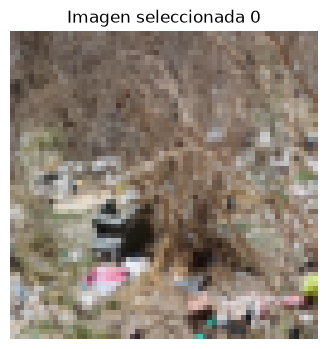

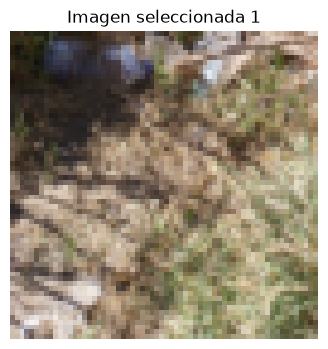

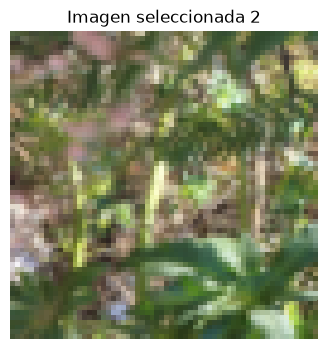

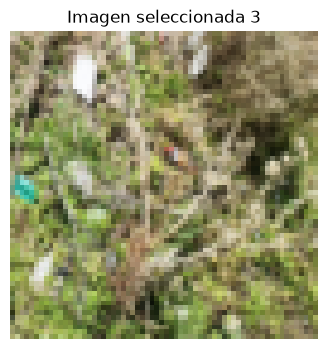

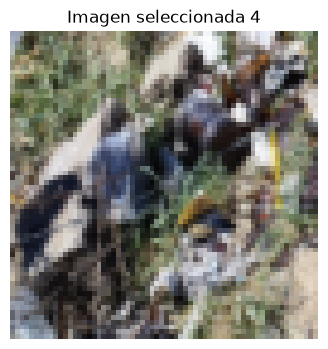

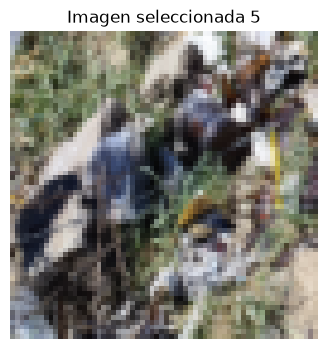

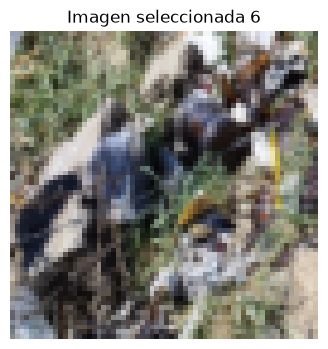

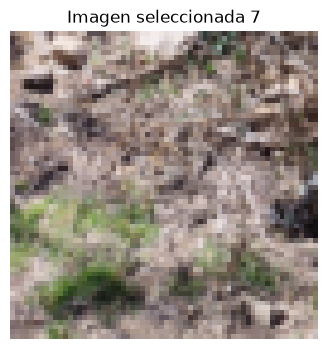

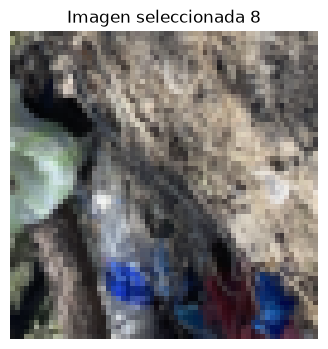

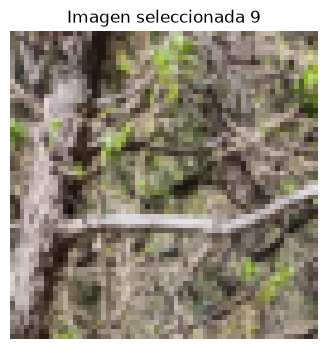

Etiquetas nuevas: [1 3 1 2 1 1 1 2 4 0]
Imágenes identificadas: 10


In [8]:
import matplotlib.pyplot as plt

n_active = 10   # cuántas imágenes quieres etiquetar

# Trozos de entrenamiento que siguen sin etiqueta
unlabeled_indices = np.where(train_mask & (y_propagated == -1))[0]

probas = log_reg_semi.predict_proba(X_trozos[unlabeled_indices])
confidence = np.max(probas, axis=1)

lowest = np.argsort(confidence)[:n_active]
active_indices = unlabeled_indices[lowest]

print("Confianza de las seleccionadas:", confidence[lowest].round(3))

menu = ", ".join(f"{i}={name}" for i, name in enumerate(CLASSES))
y_active = []

for i, idx in enumerate(active_indices):
    plt.figure(figsize=(4, 4))
    plt.imshow(X_trozos[idx].reshape(3, 64, 64).transpose(1, 2, 0))
    plt.title(f"Imagen seleccionada {i}")
    plt.axis("off")
    plt.show()

    label = int(input(f"Etiqueta ({menu}, -1=No identificable): "))
    while label not in [-1] + list(range(len(CLASSES))):
        label = int(input(f"Introduce solamente -1 o un número de 0 a {len(CLASSES) - 1}: "))
    y_active.append(label)

y_active = np.array(y_active)
print("Etiquetas nuevas:", y_active)
print("Imágenes identificadas:", np.sum(y_active != -1))


In [9]:
y_train_active = y_propagated.copy()

valid_active = y_active != -1
y_train_active[active_indices[valid_active]] = y_active[valid_active]

selected_active = y_train_active != -1
X_train_active = X_trozos[selected_active]
y_train_active_labeled = y_train_active[selected_active]

log_reg_active = LogisticRegression(max_iter=2000, random_state=42)
log_reg_active.fit(X_train_active, y_train_active_labeled)

print("Etiquetas manuales iniciales:", len(X_labeled))
print("Etiquetas manuales nuevas:", np.sum(valid_active))
print("Total utilizado:", len(X_train_active))
for c, name in enumerate(CLASSES):
    print(f"{name}: {np.sum(y_train_active_labeled == c)} imágenes")


Etiquetas manuales iniciales: 10
Etiquetas manuales nuevas: 10
Total utilizado: 171
arboles: 43 imágenes
maleza: 53 imágenes
arbusto: 2 imágenes
pasto: 1 imágenes
sin_vegetacion: 72 imágenes


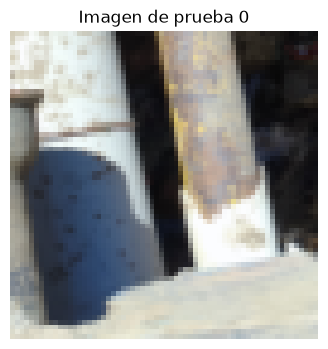

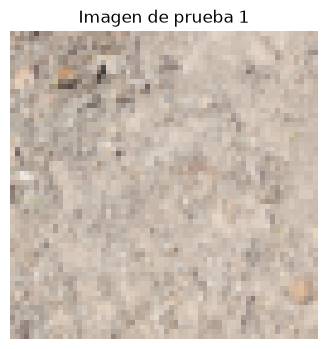

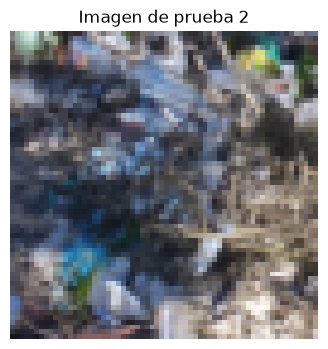

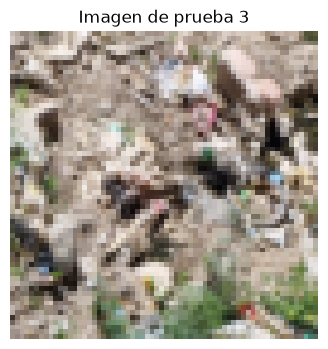

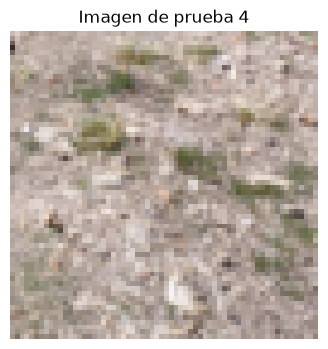

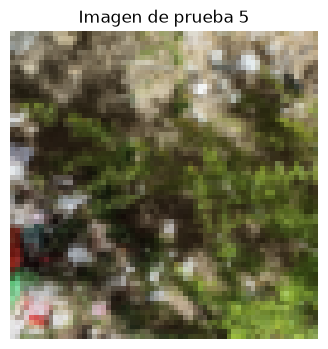

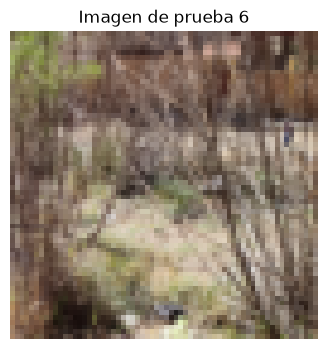

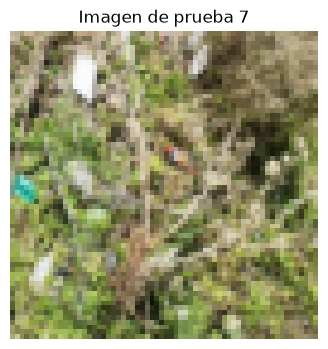

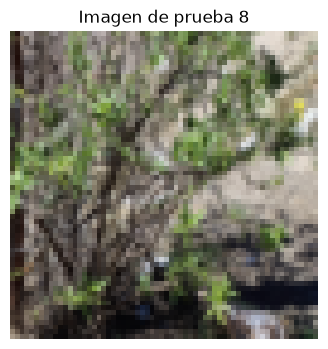

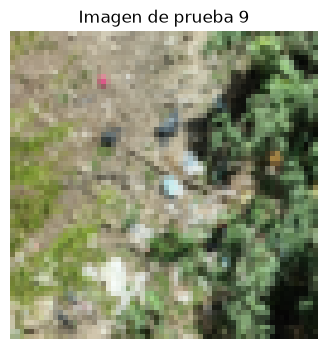

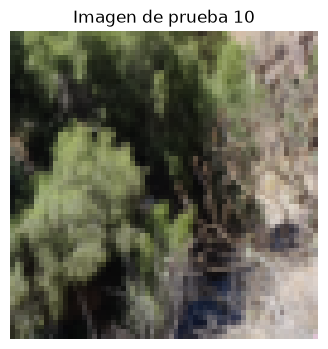

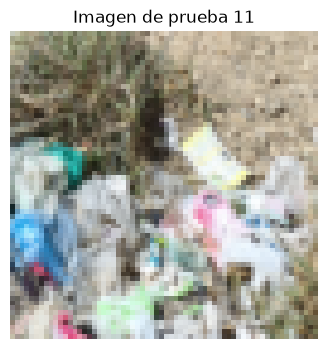

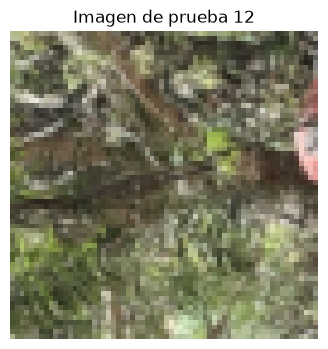

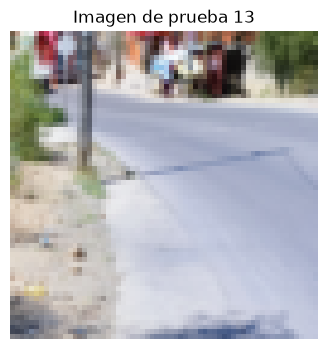

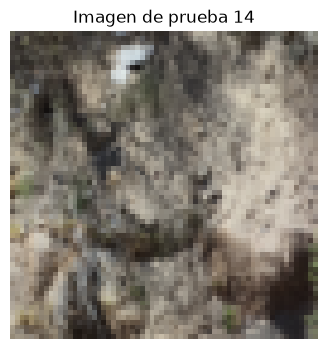

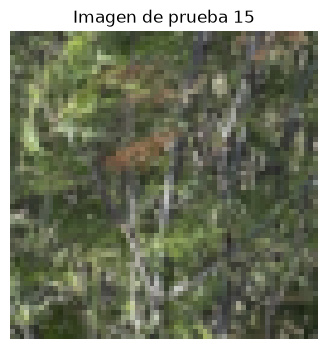

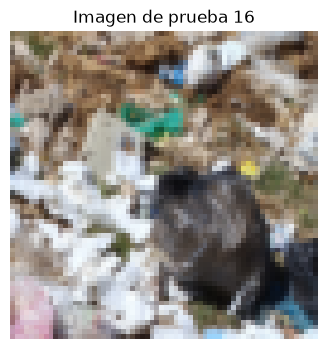

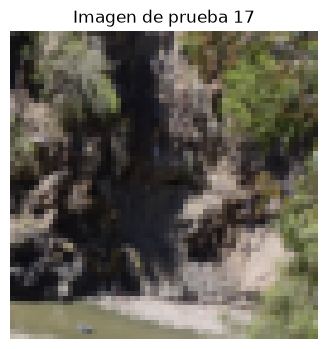

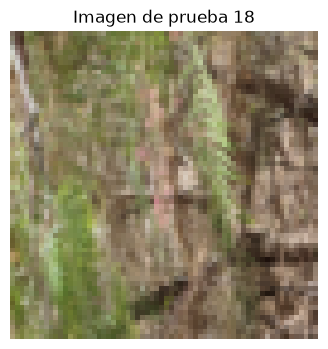

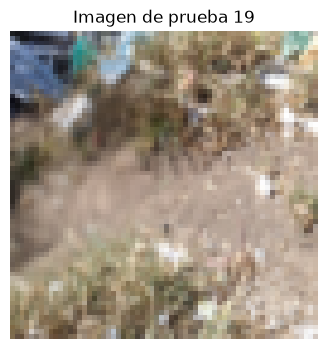

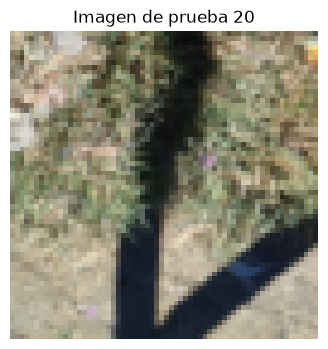

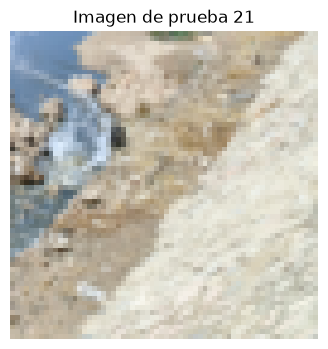

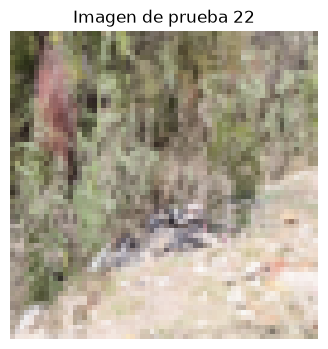

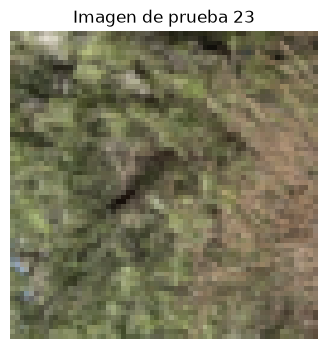

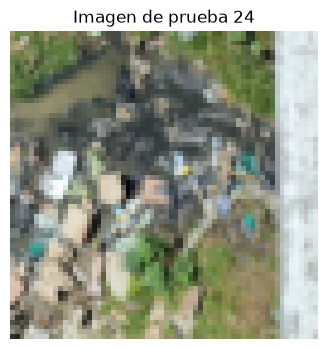

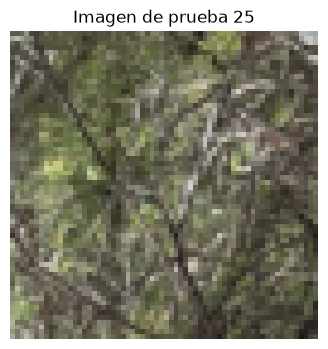

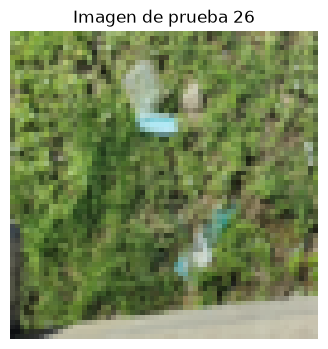

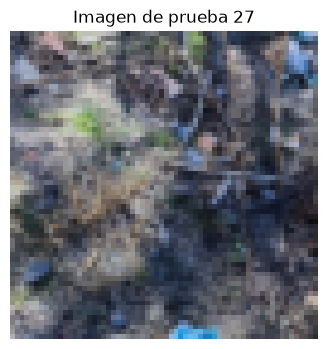

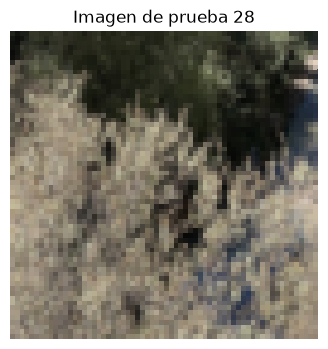

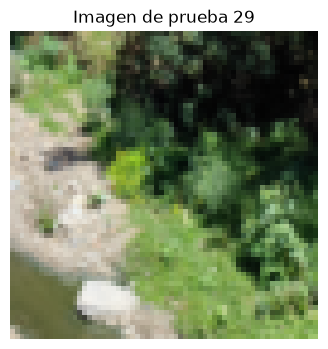

Imágenes evaluables: 30
arboles: 9 imágenes
maleza: 8 imágenes
arbusto: 4 imágenes
pasto: 4 imágenes
sin_vegetacion: 5 imágenes


In [10]:
X_test_sample = X_trozos[test_indices]
y_test_manual = []

for i in range(len(X_test_sample)):
    plt.figure(figsize=(4, 4))
    plt.imshow(X_test_sample[i].reshape(3, 64, 64).transpose(1, 2, 0))
    plt.title(f"Imagen de prueba {i}")
    plt.axis("off")
    plt.show()

    label = int(input(f"Etiqueta ({menu}, -1=No identificable): "))
    while label not in [-1] + list(range(len(CLASSES))):
        label = int(input(f"Introduce solamente -1 o un número de 0 a {len(CLASSES) - 1}: "))
    y_test_manual.append(label)

y_test_manual = np.array(y_test_manual)

valid_test = y_test_manual != -1
X_test_eval = X_test_sample[valid_test]
y_test_eval = y_test_manual[valid_test]

print("Imágenes evaluables:", len(y_test_eval))
for c, name in enumerate(CLASSES):
    print(f"{name}: {np.sum(y_test_eval == c)} imágenes")



Modelo: Inicial
Exactitud: 36.67%
F1 macro: 0.248
Aciertos: 11 de 30

Modelo: Semisupervisado
Exactitud: 30.00%
F1 macro: 0.211
Aciertos: 9 de 30

Modelo: Activo
Exactitud: 30.00%
F1 macro: 0.215
Aciertos: 9 de 30

Línea base (clase mayoritaria): 30.00%


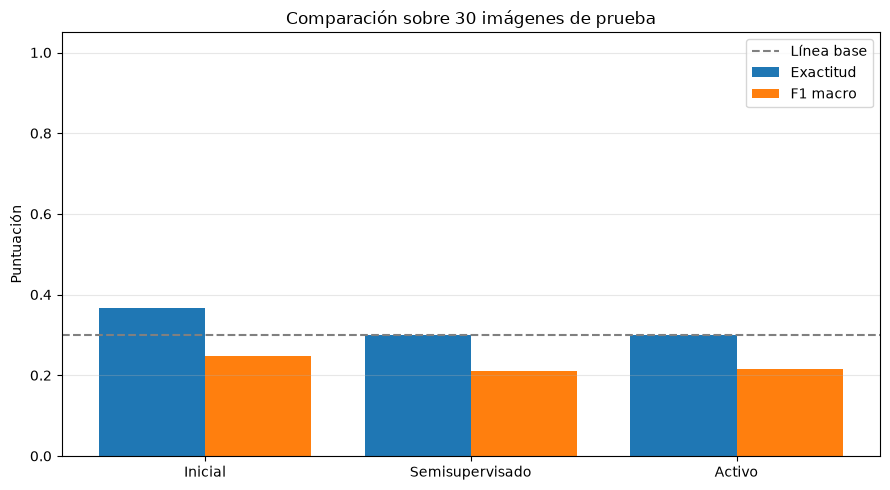

In [11]:
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Inicial": log_reg,
    "Semisupervisado": log_reg_semi,
    "Activo": log_reg_active
}

accuracies, f1_scores = [], []

for name, model in models.items():
    predictions = model.predict(X_test_eval)

    accuracy = accuracy_score(y_test_eval, predictions)
    f1 = f1_score(y_test_eval, predictions,
                  labels=np.unique(y_test_eval),
                  average="macro", zero_division=0)

    accuracies.append(accuracy)
    f1_scores.append(f1)

    print(f"\nModelo: {name}")
    print(f"Exactitud: {accuracy:.2%}")
    print(f"F1 macro: {f1:.3f}")
    print("Aciertos:", np.sum(predictions == y_test_eval), "de", len(y_test_eval))

# Línea base: responder siempre la clase más frecuente
baseline = np.bincount(y_test_eval).max() / len(y_test_eval)
print(f"\nLínea base (clase mayoritaria): {baseline:.2%}")

positions = np.arange(len(models))
plt.figure(figsize=(9, 5))
plt.bar(positions - 0.2, accuracies, width=0.4, label="Exactitud")
plt.bar(positions + 0.2, f1_scores, width=0.4, label="F1 macro")
plt.axhline(baseline, color="gray", linestyle="--", label="Línea base")
plt.xticks(positions, list(models.keys()))
plt.ylim(0, 1.05)
plt.ylabel("Puntuación")
plt.title(f"Comparación sobre {len(y_test_eval)} imágenes de prueba")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
